In [37]:
import pandas as pd
import numpy as np

In [38]:
df = pd.read_parquet("final.parquet")

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 835053 entries, 3 to 1350175
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   energy-kcal_100g    835053 non-null  float64
 1   fat_100g            835053 non-null  float64
 2   saturated-fat_100g  835053 non-null  float64
 3   carbohydrates_100g  835053 non-null  float64
 4   sugars_100g         835053 non-null  float64
 5   fiber_100g          835053 non-null  float64
 6   proteins_100g       835053 non-null  float64
 7   salt_100g           835053 non-null  float64
 8   nova_group          835053 non-null  Int64  
 9   nova_group_label    835053 non-null  string 
dtypes: Int64(1), float64(8), string(1)
memory usage: 70.9 MB


In [40]:
from google.colab import drive
drive.mount("/content/drive")      # a pop-up will ask you to allow access

import os
folder = "/content/drive/MyDrive/ML_Dataset"     # the Drive folder that holds the parquet file
print(os.listdir(folder))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['open_food_facts_2025 (1).csv', 'off_my_columns_clean.parquet', 'open_food_facts_2025_clean.csv']


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

SEED = 42
PATH = "final.parquet"

In [42]:
df = pd.read_parquet(PATH)
print(df.shape)
df.head()

(835053, 10)


,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,nova_group,nova_group_label
3,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
4,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
6,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,3,Processed foods
9,117.585012,2.576112,0.5,23.6,3.04,1.3,0.6,0.02,4,Ultra-processed foods
10,133.300000,7.700000,1.9,16.0,3.04,1.6,6.2,0.44,4,Ultra-processed foods


nova_group
1    108097
2     34384
3    179469
4    513103
Name: count, dtype: Int64
nova_group
1    12.94
2     4.12
3    21.49
4    61.45
Name: proportion, dtype: Float64


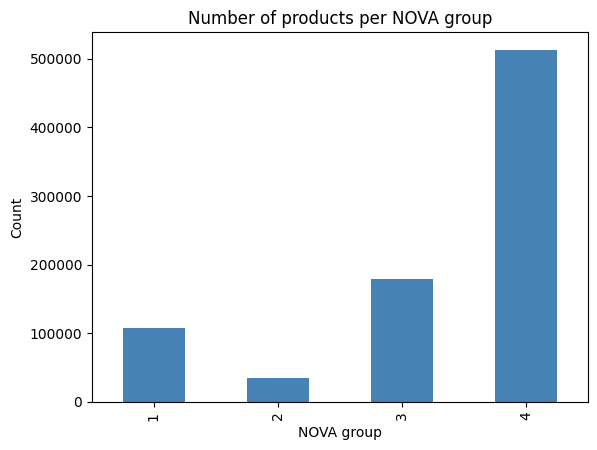

In [43]:
# Class distribution of the target
print(df["nova_group"].value_counts().sort_index())
print((df["nova_group"].value_counts(normalize=True).sort_index() * 100).round(2))

df["nova_group"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Number of products per NOVA group")
plt.xlabel("NOVA group")
plt.ylabel("Count")
plt.show()

Features and target
We use the 8 nutrient columns plus 2 ratios, giving 10 features (the handbook limit).  
`nova_group_label` is the target written as text, so it is **not** used as a feature.

In [44]:
features = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
            "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g"]

X = df[features].astype(float).copy()

# Two engineered ratios (set to 0 when the denominator is 0)
X["sugar_carb_ratio"] = np.where(X["carbohydrates_100g"] > 0, X["sugars_100g"] / X["carbohydrates_100g"], 0)
X["satfat_fat_ratio"] = np.where(X["fat_100g"] > 0, X["saturated-fat_100g"] / X["fat_100g"], 0)

# Target: NOVA groups 1-4 become 0-3 (LightGBM and XGBoost need labels starting at 0)
y = df["nova_group"].astype(int) - 1

class_names = ["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"]
print(X.shape)
print("Missing values:", X.isna().sum().sum())

(835053, 10)
Missing values: 0


In [60]:
# How often do identical nutrient vectors have different NOVA labels?
h = pd.util.hash_pandas_object(X, index=False)
g = df.assign(h=h).groupby("h")["nova_group"].agg(["size", "nunique"])
dups = g[g["size"] > 1]
print(len(dups), "repeated vectors;", round((dups["nunique"] > 1).mean() * 100, 1), "% have conflicting labels")
print("Rows that belong to a repeated vector:", round(h.duplicated(keep=False).mean() * 100, 1), "%")

37819 repeated vectors; 11.7 % have conflicting labels
Rows that belong to a repeated vector: 53.4 %


Test and Validation

In [45]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (584537, 10)  Validation: (125258, 10)  Test: (125258, 10)


In [61]:
train_hash = pd.util.hash_pandas_object(X_train, index=False)
test_hash = pd.util.hash_pandas_object(X_test, index=False)
has_twin = test_hash.isin(train_hash).values
print("Share of test rows with an exact twin in training:", round(has_twin.mean() * 100, 1), "%")

Share of test rows with an exact twin in training: 51.6 %


 Evaluation function
Each model is scored with accuracy, balanced accuracy and macro-F1.  
Accuracy alone is misleading here because NOVA 4 is the largest class.

In [46]:
results = []   # one row per model

def evaluate(name, model, X_data, y_data):
    y_pred = model.predict(X_data)
    row = {"Model": name,
           "Accuracy": accuracy_score(y_data, y_pred),
           "Balanced accuracy": balanced_accuracy_score(y_data, y_pred),
           "Macro-F1": f1_score(y_data, y_pred, average="macro")}
    results.append(row)
    print(name, "-> macro-F1 =", round(row["Macro-F1"], 4))

Baseline models
1. **Majority class:** always predicts the most common class. This is the minimum any model must beat.
2. **Logistic regression:** a simple linear model. Nutrient values are skewed, so we apply log(1+x) and then standardise them.  
   `class_weight="balanced"` gives the small classes more weight.

In [47]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
evaluate("Majority class", dummy, X_val, y_val)

Majority class -> macro-F1 = 0.1903


In [48]:
# Baseline 2: logistic regression
X_train_log = np.log1p(X_train)
X_val_log = np.log1p(X_val)
X_test_log = np.log1p(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)   # fit the scaler on training data only
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)

# This model uses the scaled data, so it is evaluated with the scaled validation set
y_pred = log_reg.predict(X_val_scaled)
results.append({"Model": "Logistic regression",
                "Accuracy": accuracy_score(y_val, y_pred),
                "Balanced accuracy": balanced_accuracy_score(y_val, y_pred),
                "Macro-F1": f1_score(y_val, y_pred, average="macro")})
print("Logistic regression -> macro-F1 =", round(results[-1]["Macro-F1"], 4))

Logistic regression -> macro-F1 = 0.51


| Model | Why we use it |
|---|---|
| Random Forest | Many decision trees averaged together. Handles non-linear relationships and skewed data without scaling. Used in earlier NOVA prediction work (Menichetti et al., 2023). |
| LightGBM | Gradient boosting: trees are built one after another, each correcting the errors of the previous ones. Fast on large data and usually very accurate on tabular data. |
| XGBoost | Another gradient boosting method with built-in regularisation, used to check that the result does not depend on one library. |

The classes are imbalanced, so every model is given class weights.

In [49]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
evaluate("Random forest", rf, X_val, y_val)

Random forest -> macro-F1 = 0.7021


In [50]:
# LightGBM
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31,
                      class_weight="balanced", random_state=SEED, verbose=-1)
lgbm.fit(X_train, y_train)
evaluate("LightGBM", lgbm, X_val, y_val)

LightGBM -> macro-F1 = 0.6766


In [51]:
# XGBoost (uses sample weights to handle the class imbalance)
weights = compute_sample_weight("balanced", y_train)

xgbc = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                     tree_method="hist", random_state=SEED)
xgbc.fit(X_train, y_train, sample_weight=weights)
evaluate("XGBoost", xgbc, X_val, y_val)

XGBoost -> macro-F1 = 0.6758


We tune LightGBM with a small grid search and 3-fold cross-validation.  
To keep it fast, the search uses a random sample of 100,000 training rows.

In [52]:
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=100000, stratify=y_train, random_state=SEED)

param_grid = {"num_leaves": [15, 31, 63],
              "learning_rate": [0.05, 0.1],
              "n_estimators": [200, 400]}

grid = GridSearchCV(LGBMClassifier(class_weight="balanced", random_state=SEED, verbose=-1),
                    param_grid, scoring="f1_macro", cv=3)
grid.fit(X_small, y_small)

print("Best parameters:", grid.best_params_)
print("Best cross-validated macro-F1:", round(grid.best_score_, 4))

Best parameters: {'learning_rate': 0.1, 'n_estimators': 400, 'num_leaves': 63}
Best cross-validated macro-F1: 0.6816


In [53]:
# Retrain LightGBM with the best parameters on the full training set
lgbm_tuned = LGBMClassifier(**grid.best_params_, class_weight="balanced", random_state=SEED, verbose=-1)
lgbm_tuned.fit(X_train, y_train)
evaluate("LightGBM (tuned)", lgbm_tuned, X_val, y_val)

LightGBM (tuned) -> macro-F1 = 0.6872


Compare the models on the validation set

In [54]:
results_val = pd.DataFrame(results).set_index("Model").sort_values("Macro-F1", ascending=False)
results_val.round(4)

,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Random forest,0.7214,0.7400,0.7021
LightGBM (tuned),0.6916,0.7314,0.6872
LightGBM,0.6796,0.7257,0.6766
XGBoost,0.6779,0.7251,0.6758
Logistic regression,0.5233,0.6276,0.5100
Majority class,0.6145,0.2500,0.1903


The test set was not used for any decision above, so these scores estimate performance on new products.

In [55]:
test_results = []

def test_row(name, y_pred):
    test_results.append({"Model": name,
                         "Accuracy": accuracy_score(y_test, y_pred),
                         "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
                         "Macro-F1": f1_score(y_test, y_pred, average="macro")})

test_row("Majority class", dummy.predict(X_test))
test_row("Logistic regression", log_reg.predict(X_test_scaled))
test_row("Random forest", rf.predict(X_test))
test_row("LightGBM", lgbm.predict(X_test))
test_row("LightGBM (tuned)", lgbm_tuned.predict(X_test))
test_row("XGBoost", xgbc.predict(X_test))

results_test = pd.DataFrame(test_results).set_index("Model").sort_values("Macro-F1", ascending=False)
results_test.round(4)

,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Random forest,0.7212,0.7389,0.7039
LightGBM (tuned),0.6929,0.7325,0.6903
LightGBM,0.6813,0.7266,0.6793
XGBoost,0.6789,0.7249,0.6773
Logistic regression,0.5248,0.6315,0.5122
Majority class,0.6145,0.2500,0.1903


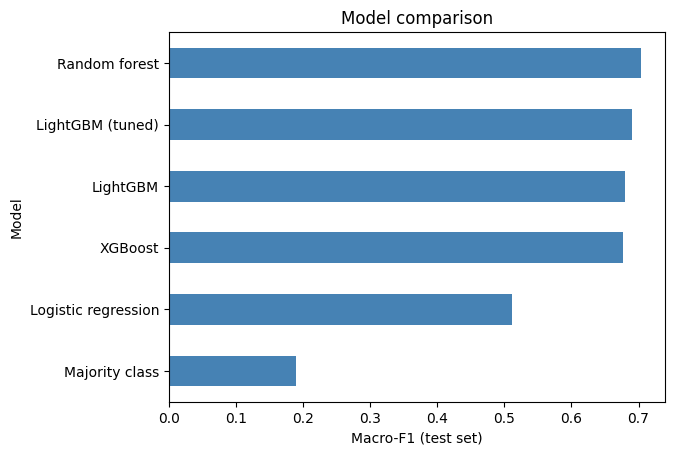

In [56]:
results_test["Macro-F1"].sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Macro-F1 (test set)")
plt.title("Model comparison")
plt.show()

In [57]:
best_model = rf
y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best, target_names=class_names, digits=3))

              precision    recall  f1-score   support

      NOVA 1      0.559     0.801     0.659     16215
      NOVA 2      0.785     0.819     0.801      5157
      NOVA 3      0.527     0.593     0.558     26921
      NOVA 4      0.862     0.742     0.798     76965

    accuracy                          0.721    125258
   macro avg      0.683     0.739     0.704    125258
weighted avg      0.747     0.721     0.728    125258



In [62]:
for name, mask in [("with twin", has_twin), ("no twin", ~has_twin)]:
    if mask.sum() > 0:
        print(name, "| rows:", mask.sum(), "| macro-F1:",
              round(f1_score(y_test.values[mask], y_pred_best[mask], average="macro"), 4))

with twin | rows: 64580 | macro-F1: 0.6505
no twin | rows: 60678 | macro-F1: 0.7701


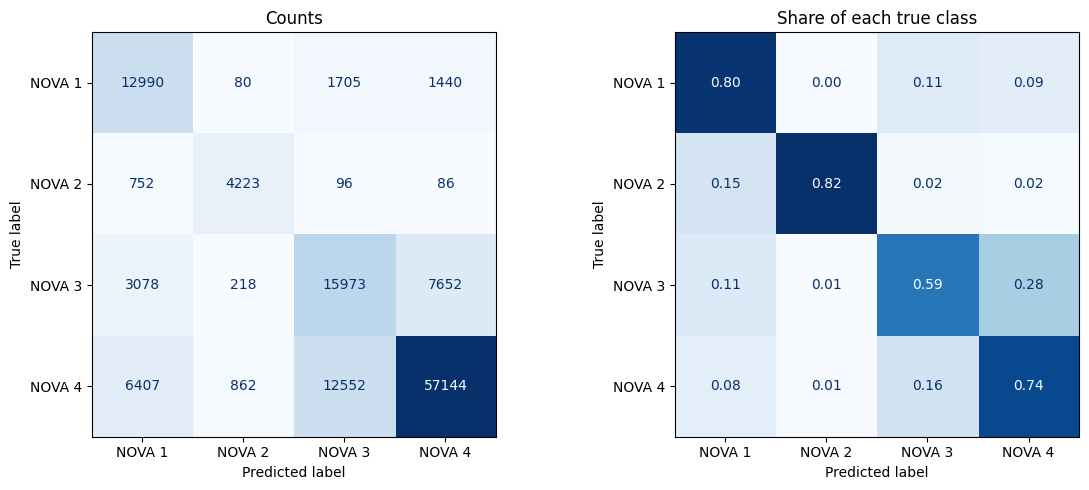

In [58]:
# Confusion matrix: counts and percentages per true class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names,
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Share of each true class")
plt.tight_layout()
plt.show()

Which features matter?
Permutation importance: shuffle one feature and see how much macro-F1 drops. A bigger drop means a more important feature.

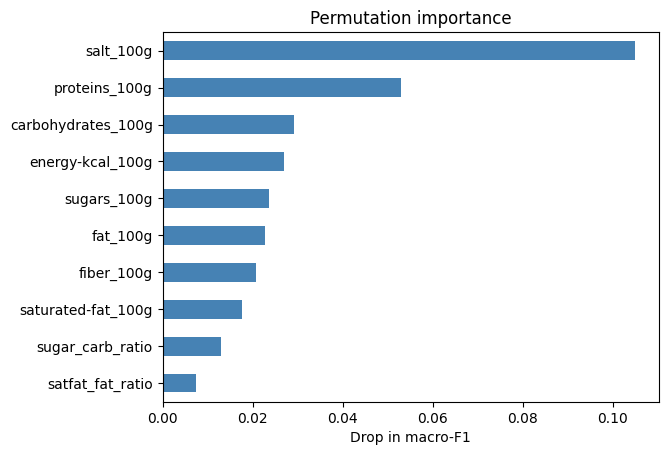

In [59]:
sample = X_val.sample(20000, random_state=SEED)
imp = permutation_importance(best_model, sample, y_val.loc[sample.index],
                             scoring="f1_macro", n_repeats=3, random_state=SEED)

importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importance.plot(kind="barh", color="steelblue")
plt.xlabel("Drop in macro-F1")
plt.title("Permutation importance")
plt.show()